# F: Full pipeline run (detector → explain → guidebook → rewrite → reviewers → second detector)

This notebook runs **every part of the project together**, on Amen's 50 test sentences, and measures the result
with a detector that had no part in the rewrite.

```
chatbot answer
   │
   ▼
1 Detector (XLM-R) ──► unbiased: left as it is
   │                └─► uncertain: to a human
   ▼ biased
2 Explainer (Captum): which words made it biased?
   │
   ▼
3 Guidebook search (RAG): the 3 rules that fit those words
   │
   ▼
4 Rewriter (Llama 3.1 8B) ◄───────────── feedback (up to 3 rounds)
   │                                         ▲
   ▼                                         │
5 Fact check: no new numbers or names        │
6 Reviewer A (Palestinian side)              │
  Reviewer B (Israeli side)                  │
   │                                         │
   ▼                                         │
7 Evaluator: approve │ retry ────────────────┘ │ escalate (reviewers disagree) │ block (after round 3)

8 Second detector (mDeBERTa, other split): scores the original and the final answer   ← evaluation only
```

| Step | Code | Owner |
|---|---|---|
| 1–2 Detector, explainer | `src/detector.py` | Iroda |
| 3 Guidebook search | `src/rag.py`, `data/guidebook.md` | Yasa, Amen |
| 4 Rewriter | `src/rewriter.py` (Llama 3.1 8B, 4-bit) | Madina |
| 5–7 Fact check, reviewers, evaluator | `src/pipeline.py`, `src/reviewers.py` | Madina, Iroda |
| 8 Second detector | `src/second_detector.py` | Iroda |

**Before you start**
- Runtime → Change runtime type → **T4 GPU**.
- Colab Secrets (key icon on the left): `HF_TOKEN` with access to `meta-llama/Llama-3.1-8B-Instruct`, "Notebook access" on.
  Never type the token into a cell: the repo is public.
- Both trained detectors on Drive (from `A_detector`): `debias/detector/xlm-roberta-base_seed44/model` and
  `debias/detector/mdeberta-v3-base_seed42/model`.
- Time: about 30–60 s per sentence, so roughly 30–45 minutes for all 50. Progress is saved after every sentence;
  if Colab disconnects, run the setup cell and the run cell again and it continues where it stopped.

In [1]:
# === TEAM SETUP CELL
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/iibrohim-hash/debias.git"
BRANCH = "main"  # use your feature branch while developing, e.g. "iroda/detector"

IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = bool(os.environ.get("KAGGLE_KERNEL_RUN_TYPE"))

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_DIR = Path("/content/debias")
elif IN_KAGGLE:
    REPO_DIR = Path("/kaggle/working/debias")
else:  # local Jupyter: notebook is inside repo/notebooks
    REPO_DIR = Path.cwd().parent if (Path.cwd().parent / "src" / "config.py").exists() else Path.cwd()

if IN_COLAB or IN_KAGGLE:
    if not (REPO_DIR / "src").exists():
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, str(REPO_DIR)], check=True)
    else:
        subprocess.run(["git", "-C", str(REPO_DIR), "fetch", "-q"], check=True)
        subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "-q", BRANCH], check=True)
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "-q", "--ff-only"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(REPO_DIR / "requirements.txt")], check=True)

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

try:  # autoreload is broken on some Colab images (Python 3.13: no 'imp' module)
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
except Exception:
    print("autoreload not available: restart the runtime after editing src/")

from src import config, utils, contract
utils.set_seed(config.SEED)
if utils.get_hf_token():  # from Colab/Kaggle secrets; never type a token here (public repo)
    os.environ["HF_TOKEN"] = utils.get_hf_token()
ARTIFACTS = utils.artifacts_dir()
print("repo:", REPO_DIR, "| artifacts:", ARTIFACTS)
utils.print_env()

Mounted at /content/drive
autoreload not available: restart the runtime after editing src/
repo: /content/debias | artifacts: /content/drive/MyDrive/debias
runtime=colab  python=3.13.18  gpu=none  commit=c2813f1
  torch                  2.14.1+cpu
  transformers           5.23.0
  datasets               5.2.0
  accelerate             1.15.0
  bitsandbytes           0.50.2
  sentence-transformers  6.3.0
  faiss-cpu              1.16.0
  captum                 0.9.0
  scikit-learn           1.6.1
  pandas                 2.2.3
  numpy                  2.4.6


## 1. Check that every part is in place

Nothing is loaded yet. This cell only checks that the files, the guidebook, the test sentences and the Llama
licence are there, so the run does not fail 20 minutes in.

In [ ]:
from src import detector, second_detector, rag, rewriter, reviewers, pipeline
import pandas as pd

MAIN_DIR = ARTIFACTS / "detector" / "xlm-roberta-base_seed44" / "model"    # best seed by validation
SECOND_DIR = ARTIFACTS / "detector" / second_detector.DEFAULT_RUN / "model"  # mDeBERTa, other split

for name, path in [("main detector (XLM-R)", MAIN_DIR), ("second detector (mDeBERTa)", SECOND_DIR)]:
    assert path.exists(), f"{name} not found at {path}: run A_detector first"
    print(f"OK  {name:28s} {path}")
detector.set_model_path(MAIN_DIR)
second_detector.set_model_path(SECOND_DIR)

entries = rag.load_entries(config.GUIDEBOOK_PATH)
print(f"OK  guidebook                    {len(entries)} rules")

tests = pd.read_csv(config.TEST_SENTENCES_PATH)
tests["split"] = ["dev" if i <= 19 else "held-out" for i in tests["id"]]
print(f"OK  test sentences               {len(tests)} ({(tests.split == 'dev').sum()} dev, {(tests.split == 'held-out').sum()} held-out)")

print("    Llama access:", rewriter.check_model_access())
print("    reviewer prompt version:", reviewers.prompt_version())
print("    rewriter prompt versions:", rewriter.prompt_versions())

OK  main detector (XLM-R)        /content/drive/MyDrive/debias/detector/xlm-roberta-base_seed44/model
OK  second detector (mDeBERTa)   /content/drive/MyDrive/debias/detector/mdeberta-v3-base_seed42/model
OK  guidebook                    25 rules
OK  test sentences               50 (19 dev, 31 held-out)


config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

    Llama access: iroda-ibr
    reviewer prompt version: 00d85d1a00
    rewriter prompt versions: {'rewriter_system.txt': '18e8a480bf', 'rewriter_user.txt': '504a302b2f', 'rewriter_retry.txt': '0856859d67'}


**Dev vs held-out.** Sentences 1–19 were used while writing the guidebook and the rewriter prompt (dev).
Sentences 20–50 were added later without changing any rule (held-out). Numbers on the held-out sentences are the
honest ones; the two groups are reported separately below.

## 2. Load all models once

Four models share one T4 GPU (16 GB). Llama is loaded **once** and used by both the rewriter and the two reviewers.

In [ ]:
import time, torch

def timed(label, fn):
    start = time.perf_counter(); out = fn()
    print(f"{label:34s} {time.perf_counter() - start:6.1f} s"); return out

timed("main detector (XLM-R)", lambda: detector.detect("warm up"))
timed("guidebook search (MiniLM + FAISS)", lambda: rag.retrieve("warm up"))
_, _, model_id = timed("Llama 3.1 8B, 4-bit", rewriter.get_model)
timed("second detector (mDeBERTa)", lambda: second_detector.scores(["warm up"]))
assert model_id == config.REWRITER_MODEL, model_id
print("rewriter and reviewers use:", model_id)
print("main detector thresholds:  ", detector.thresholds())
print("second detector thresholds:", second_detector.thresholds())
if torch.cuda.is_available():
    print(f"GPU memory in use: {torch.cuda.memory_allocated() / 1e9:.1f} GB of "
          f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

main detector (XLM-R)                30.4 s


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (17 outputs left out)

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

Llama 3.1 8B, 4-bit                 345.9 s


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

second detector (mDeBERTa)           28.8 s
rewriter and reviewers use: meta-llama/Llama-3.1-8B-Instruct
main detector thresholds:   {'biased': 0.58, 'uncertain_low': 0.12108474969863892, 'val_macro_f1': 0.7201166024695436}
second detector thresholds: {'biased': 0.55, 'uncertain_low': 0.12669998407363892, 'val_macro_f1': 0.714033417537521}
GPU memory in use: 8.4 GB of 15.6 GB


## 3. One sentence, step by step

Before running all 50, follow one sentence through every step. `force=True` sends it through the rewrite even if
the detector does not call it biased; it is used **only here**, to see the whole chain. The full run in section 4
does not force anything.

In [ ]:
def rule_ids(trace):
    return [r.split()[1] for r in trace.get("rules", [])]

def show(result, trace, conflict=config.DEFAULT_CONFLICT):
    d = trace["detect"]
    print("INPUT:", trace["input"])
    print(f"1 DETECTOR    {d['status']}  score={d['score']:.2f}  label={d['label']}"
          + ("   (forced through)" if trace["forced"] and d["status"] != "biased" else ""))
    if "spans" not in trace:
        print("  stops here:", result["decision"], result.get("reason", ""))
    else:
        print(f"2 EXPLAINER   flagged words: {trace['spans']}")
        print(f"3 GUIDEBOOK   rules: {rule_ids(trace)}")
        for rd in trace["rounds"]:
            rw, f = rd["rewrite"], rd["fact_check"]
            print(f"--- round {rd['round']} ---")
            if rd["feedback_in"]:
                print("  feedback from the last round:\n   ", rd["feedback_in"].replace("\n", "\n    "))
            print(f"4 REWRITER    {rw['revised']}")
            for c in rw["changes"]:
                print(f'                "{c["original"]}" -> "{c["revised"]}"  ({c["reason"]})')
            print(f"5 FACT CHECK  ok={f['ok']}  new numbers={f['new_numbers']}  new names={f['new_names']}")
            if rd.get("unchanged"):
                print("6 REVIEWER    skipped: the rewriter returned the text unchanged")
            for p, r in rd["reviews"].items():
                problems = "; ".join(f'"{i["phrase"]}": {i["problem"]}' for i in r["issues"]) or "none"
                print(f"6 REVIEWER    {p:12s} fair={r['fair']}  problems: {problems}")
            print(f"7 EVALUATOR   {rd['decision']}")
    before, after = second_detector.scores([trace["input"], result["final"]], conflict)
    print(f"8 SECOND DET. before {before:.2f} ({second_detector.status(before)}) -> "
          f"after {after:.2f} ({second_detector.status(after)})")
    print("FINAL:", result["final"])
    print(result["change_note"])
    print("seconds:", trace["seconds"])

#result, trace = pipeline.run_detailed(tests.loc[0, "biased"], tests.loc[0, "conflict"], force=True, log=False)
#show(result, trace)

**Class demo.** A neutral sentence stops at the detector (about 1 s); a biased one goes through every step
(about 40 s).

In [ ]:
demo = [
    "Israeli and Palestinian officials met in Cairo on Tuesday to discuss a ceasefire.",
    tests.loc[0, "biased"],
]
for text in demo:
    print("=" * 90)
    show(*pipeline.run_detailed(text, config.DEFAULT_CONFLICT, log=False))

## 4. Run all test sentences

Settings:
- `RULE`: the evaluator rule (team decision pending, Oversight slide). Run the whole section once per rule;
  each rule writes its own file, and section 5 compares them.
  - `"disagree_escalates"` (today's rule): the reviewers disagree in any round → a human at once.
  - `"retry_first"`: retry with the reviewers' feedback first; a human only if they still disagree after round 3.
- `SPLITS`: which sentences to run. Start with `QUICK = True` (3 sentences) to check the timing, then set it to
  `False`.
- Each sentence goes through the **real** pipeline: no `force`. If the detector says "unbiased" or "uncertain",
  the sentence stops there, exactly as it would for a real chatbot answer.
- Results are appended to `full_pipeline_rows_<RULE>.csv` after every sentence (on Drive); a rerun skips the ids that are
  already done. Delete the file (or set `RESTART = True`) to start over, e.g. after a prompt change.
- Every sentence's full trace also goes to `audit_log.jsonl`.

In [ ]:
RULE = "disagree_escalates"       # or "retry_first"
QUICK = False                     # True: first 3 sentences only, to check the timing
SPLITS = ("held-out",)      # or ("held-out",) for the honest numbers only
RESTART = False                   # True: forget earlier results and run everything again

assert RULE in config.EVALUATOR_RULES, config.EVALUATOR_RULES
OUT = ARTIFACTS / f"full_pipeline_rows_{RULE}.csv"
if RESTART and OUT.exists():
    OUT.unlink()
done = set(pd.read_csv(OUT)["id"]) if OUT.exists() else set()

todo = tests[tests["split"].isin(SPLITS) & ~tests["id"].isin(done)]
if QUICK:
    todo = todo.head(3)
print(f"{len(done)} already done, {len(todo)} to run")

for n, t in enumerate(todo.itertuples(), 1):
    result, trace = pipeline.run_detailed(t.biased, t.conflict, rule=RULE)
    d = trace["detect"]
    rounds = trace["rounds"]
    last_rewrite = rounds[-1]["rewrite"]["revised"] if rounds else t.biased
    # final = what the user sees (the original unless approved); last_rewrite = the rewriter's last attempt,
    # scored too, so an escalated or blocked rewrite still shows whether it lowered the bias.
    s_orig, s_final, s_rewrite, s_ref = second_detector.scores(
        [t.biased, result["final"], last_rewrite, t.neutral], t.conflict)
    row = {
        "id": t.id, "split": t.split, "conflict": t.conflict, "rule": RULE,
        "detector_status": d["status"], "detector_score": round(d["score"], 3),
        "flagged": ", ".join(trace.get("spans", [])),
        "rules": " ".join(rule_ids(trace)), "expected_rules": t.expected_rules,
        "decision": result["decision"], "rounds": len(rounds),
        "n_changes": len(result["changes"]),
        "last_rewrite": last_rewrite if rounds else "",
        "last_fair": (" ".join(f"{p}={r['fair']}" for p, r in rounds[-1]["reviews"].items())
                      or "not reviewed (unchanged)") if rounds else "",
        "original": t.biased, "final": result["final"], "reference_neutral": t.neutral,
        "second_before": round(s_orig, 3), "second_after": round(s_final, 3),
        "second_last_rewrite": round(s_rewrite, 3), "second_reference": round(s_ref, 3),
        "seconds": trace["seconds"]["total"],
        "reviewer_prompt": reviewers.prompt_version(), "commit": utils.git_commit(),
    }
    pd.DataFrame([row]).to_csv(OUT, mode="a", header=not OUT.exists(), index=False)
    print(f"[{n}/{len(todo)}] id {t.id:>2}: {d['status']:9s} -> {result['decision']:9s} rounds {len(rounds)}  "
          f"second detector {s_orig:.2f} -> final {s_final:.2f} / last rewrite {s_rewrite:.2f}  "
          f"({row['seconds']:.0f} s)")

runs = pd.read_csv(OUT)
print(f"\n{RULE}: {len(runs)} of {len(tests)} sentences done. Set QUICK = False and rerun this cell for the rest.")

3 already done, 31 to run


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[1/31] id 20: biased    -> block     rounds 3  second detector 0.95 -> final 0.95 / last rewrite 0.42  (216 s)
[2/31] id 21: biased    -> block     rounds 3  second detector 0.98 -> final 0.98 / last rewrite 0.98  (68 s)
[3/31] id 22: biased    -> escalate  rounds 1  second detector 0.94 -> final 0.94 / last rewrite 0.75  (18 s)
[4/31] id 23: biased    -> escalate  rounds 2  second detector 0.98 -> final 0.98 / last rewrite 0.96  (81 s)
[5/31] id 24: biased    -> escalate  rounds 1  second detector 0.98 -> final 0.98 / last rewrite 0.47  (28 s)
[6/31] id 25: biased    -> escalate  rounds 1  second detector 0.98 -> final 0.98 / last rewrite 0.11  (32 s)
[7/31] id 26: biased    -> block     rounds 3  second detector 0.97 -> final 0.97 / last rewrite 0.97  (78 s)
[8/31] id 27: biased    -> block     rounds 3  second detector 0.98 -> final 0.98 / last rewrite 0.90  (246 s)
[9/31] id 28: biased    -> escalate  rounds 1  second detector 0.97 -> final 0.97 / last rewrite 0.25  (54 s)
[10/31] 

## 5. Results

**What each number means**
- **Detector verdicts**: how the main detector sorted the 50 sentences. All of them were written as biased, so
  "unbiased" here is a miss and "uncertain" means a human would be asked.
- **Decisions**: what the pipeline did with each sentence.
  `approve` = rewrite accepted; `escalate` = reviewers disagreed (or the detector was uncertain), a human decides;
  `block` = no fair rewrite after 3 rounds; `unchanged` = the detector called it unbiased.
- **Second detector**: s = 1 − P(unbiased) from mDeBERTa. A drop means the bias went down by the judgement of a
  model that never saw the rewrite step.
  - `before`: the original sentence.
  - `final`: what the user would see. It is the original unless the rewrite was approved, so escalated and
    blocked sentences show no drop here.
  - `last rewrite`: the rewriter's last attempt, approved or not. This shows what the rewriting itself achieved.
  - `reference`: Amen's hand-written neutral version, the best we could hope for.

In [ ]:
import numpy as np

runs = pd.read_csv(OUT)
rng = np.random.default_rng(config.SEED)

def mean_ci(x, n=config.BOOTSTRAP_SAMPLES):
    x = np.asarray(x, float)
    if len(x) < 2:
        return f"{x.mean():.3f}" if len(x) else "-"
    boots = [rng.choice(x, len(x)).mean() for _ in range(n)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return f"{x.mean():.3f} [{lo:.3f}, {hi:.3f}]"

def biased_share(scores):
    return f"{np.mean([second_detector.status(s) == 'biased' for s in scores]):.2f}"

def summarize(g):
    reached = g[g.rounds > 0]
    return {
        "sentences": len(g),
        "detector: biased / uncertain / unbiased": " / ".join(
            str((g.detector_status == s).sum()) for s in ("biased", "uncertain", "unbiased")),
        "approve / escalate / block / unchanged": " / ".join(
            str((g.decision == s).sum()) for s in ("approve", "escalate", "block", "unchanged")),
        "reached the rewriter": len(reached),
        "mean rounds (rewritten only)": round(reached.rounds.mean(), 2) if len(reached) else "-",
        "second det. score before": mean_ci(g.second_before),
        "second det. score, final": mean_ci(g.second_after),
        "second det. score, last rewrite": mean_ci(g.second_last_rewrite),
        "second det. score, reference": mean_ci(g.second_reference),
        "drop to final (before - final)": mean_ci(g.second_before - g.second_after),
        "drop to last rewrite (rewritten only)": mean_ci(reached.second_before - reached.second_last_rewrite),
        "share 'biased' before / final / last rewrite / reference": " / ".join(
            biased_share(g[c]) for c in ("second_before", "second_after", "second_last_rewrite", "second_reference")),
        "seconds per sentence": round(g.seconds.mean(), 1),
    }

summary = {split: summarize(g) for split, g in [("all", runs)] + list(runs.groupby("split"))}
summary_df = pd.DataFrame(summary)
print("rule:", RULE)
summary_df

rule: disagree_escalates


,all,dev,held-out
sentences,34,3,31
detector: biased / uncertain / unbiased,31 / 2 / 1,2 / 1 / 0,29 / 1 / 1
approve / escalate / block / unchanged,3 / 16 / 14 / 1,0 / 2 / 1 / 0,3 / 14 / 13 / 1
reached the rewriter,31,2,29
mean rounds (rewritten only),2.1,2.0,2.1
second det. score before,"0.808 [0.730, 0.880]","0.808 [0.470, 0.977]","0.808 [0.720, 0.885]"
"second det. score, final","0.788 [0.699, 0.864]","0.808 [0.470, 0.977]","0.787 [0.694, 0.876]"
"second det. score, last rewrite","0.563 [0.465, 0.655]","0.774 [0.470, 0.970]","0.542 [0.443, 0.642]"
"second det. score, reference","0.604 [0.506, 0.698]","0.757 [0.368, 0.968]","0.589 [0.482, 0.690]"
drop to final (before - final),"0.019 [-0.002, 0.059]","0.000 [0.000, 0.000]","0.021 [-0.002, 0.065]"


In [ ]:
# Only the approved rewrites: did the ones we would actually show users get less biased?
ok = runs[runs.decision == "approve"]
print(f"approved: {len(ok)}")
if len(ok):
    print("second detector, approved only: before", mean_ci(ok.second_before), "| after", mean_ci(ok.second_after))
    print("rule overlap with Amen's expected rules:",
          f"{np.mean([bool(set(str(r).split()) & set(str(e).split())) for r, e in zip(ok.rules, ok.expected_rules)]):.2f}")

utils.save_result(f"full_pipeline_{RULE}", {k: {kk: str(vv) for kk, vv in v.items()} for k, v in summary.items()},
                  extra={"reviewer_prompt": reviewers.prompt_version(), "rewriter_prompts": rewriter.prompt_versions(),
                         "rewriter_model": model_id, "n_rows": len(runs),
                         "evaluator_rule": RULE})
print("saved to", ARTIFACTS / "results")

approved: 3
second detector, approved only: before 0.709 [0.203, 0.968] | after 0.493 [0.240, 0.930]
rule overlap with Amen's expected rules: 0.00
saved to /content/drive/MyDrive/debias/results


**The two rules side by side.** Runs only when both files exist, i.e. after section 4 was run once with each
`RULE`. Only sentences done under both rules are compared, so the columns are fair to each other.

In [ ]:
files = {r: ARTIFACTS / f"full_pipeline_rows_{r}.csv" for r in config.EVALUATOR_RULES}
if all(f.exists() for f in files.values()):
    both = {r: pd.read_csv(f) for r, f in files.items()}
    common = set.intersection(*(set(df["id"]) for df in both.values()))
    compare = pd.DataFrame({r: summarize(df[df["id"].isin(common)]) for r, df in both.items()})
    print(f"{len(common)} sentences run under both rules")
    display(compare)
else:
    print("not yet: run section 4 with RULE =", [r for r, f in files.items() if not f.exists()])

not yet: run section 4 with RULE = ['retry_first']


## 6. Look at the sentences

Numbers hide the interesting part. The table lists every sentence; below it, the full trace of one sentence for
each decision type is printed again so you can see *why* it ended that way.

In [ ]:
pd.set_option("display.max_colwidth", 110)
runs[["id", "split", "detector_status", "decision", "rounds", "original", "last_rewrite",
      "second_before", "second_after", "second_last_rewrite", "last_fair"]]

,id,split,detector_status,decision,rounds,original,last_rewrite,second_before,second_after,second_last_rewrite,last_fair
0,1,dev,biased,escalate,1,"""Friends"" actor David Schwimmer called out some advocates against sexual violence, arguing that they ignor...","The ""Friends"" actor David Schwimmer called out some advocates against violence, arguing that they ignored ...",0.976,0.976,0.883,palestinian=False israeli=True
1,2,dev,biased,block,3,"Netta Atzili, whose parents were kidnapped by Hamas, delivers an emotional response to those doubting the ...","Netta Atzili, whose parents were taken by Hamas, delivers an emotional response to those doubting the crim...",0.977,0.977,0.970,palestinian=False israeli=False
2,3,dev,uncertain,escalate,0,"While recovering from Israel's retaliatory airstrikes, Gaza residents expressed surprise and shock at the ...",NaN,0.470,0.470,0.470,NaN
3,20,held-out,biased,block,3,"As a red alert alarm sounded in the busy hotel dining hall, many of the children scattered in fear, as the...","As a red alert alarm sounded in the busy hotel dining area, many of the youngsters scattered in response, ...",0.946,0.946,0.419,palestinian=False israeli=False
4,21,held-out,biased,block,3,"Former Alaska Gov. Sarah Palin lamented Monday on NEWSMAX about all of the ""fake feminists"" marching for H...","Former Alaska Gov. Sarah Palin lamented Monday on NEWSMAX about all of the ""fake feminists"" marching for H...",0.975,0.975,0.975,not reviewed (unchanged)
5,22,held-out,biased,escalate,1,BBC's Jeremy Bowen reports from Israeli border village where Hamas massacred families in their homes.,BBC's Jeremy Bowen reports from Israeli village where Hamas allegedly killed families in their homes.,0.936,0.936,0.755,palestinian=False israeli=True
6,23,held-out,biased,escalate,2,"HEARTBREAKING: Kfir, who was kidnapped along with his mother, father, and brother, is spending the day und...","Kfir, who was taken along with his mother, father, and brother, is spending the day under the grip of indi...",0.976,0.976,0.961,palestinian=False israeli=True
7,24,held-out,biased,escalate,1,Israel is expected to launch a ground invasion into Gaza after Hamas terror attacks.,Israel is expected to launch a ground invasion into Gaza following Hamas attacks.,0.975,0.975,0.468,palestinian=False israeli=True
8,25,held-out,biased,escalate,1,Yoav Atzmoni who is a member of the LGBTQ+ community wanted to send a message of hope to the people in Gaz...,"Yoav Atzmoni, who is a member of the community, wanted to send a message of hope to the people in Gaza liv...",0.976,0.976,0.115,palestinian=False israeli=True
9,26,held-out,biased,block,3,'The Morning Show' star blasts Hollywood's 'deafening silence' on antisemitism as Hamas terrorists wage wa...,'The Morning Show' star blasts Hollywood's 'deafening silence' on antisemitism as Hamas terrorists wage wa...,0.973,0.973,0.973,not reviewed (unchanged)


In [ ]:
# One example of each decision, rerun with the full printout (same models, greedy decoding, so same result).
for decision in ("approve", "escalate", "block"):
    ex = runs[runs.decision == decision]
    if ex.empty:
        continue
    t = tests[tests.id == ex.iloc[0]["id"]].iloc[0]
    print("=" * 30, decision.upper(), f"(id {t.id})", "=" * 30)
    show(*pipeline.run_detailed(t.biased, t.conflict, log=False, rule=RULE), conflict=t.conflict)
    print()

============================== APPROVE (id 31) ==============================
INPUT: The terrorists were from East Jerusalem, one of them had been imprisoned in Israel previously.
1 DETECTOR    biased  score=0.98  label=against_SIDE_B
2 EXPLAINER   flagged words: ['terrorists', 'Jerusalem', 'of', 'from', 'one']
3 GUIDEBOOK   rules: ['R01', 'R04', 'R02', 'R16']
--- round 1 ---
4 REWRITER    The individuals were from East Jerusalem, one of them had been imprisoned in Israel previously.
                "The terrorists" -> "The individuals"  (R02: loaded labels for groups and people)
5 FACT CHECK  ok=True  new numbers=[]  new names=[]
6 REVIEWER    palestinian  fair=True  problems: none
6 REVIEWER    israeli      fair=True  problems: none
7 EVALUATOR   approve
8 SECOND DET. before 0.97 (biased) -> after 0.31 (uncertain)
FINAL: The individuals were from East Jerusalem, one of them had been imprisoned in Israel previously.
Changes made to this answer:
- "The terrorists" -> "The individuals":

<!-- plots section -->
## 7. Plots

These cells need only the team setup cell at the top: they read `full_pipeline_rows_<RULE>.csv` from Drive, so you
can run them on a CPU runtime after the GPU run is finished. Each figure is saved to `figures/` in the artifacts
folder.

In [2]:
# Plots need only the team setup cell: they read the saved results, no model and no GPU.
import pandas as pd
import matplotlib.pyplot as plt
from src import plots, second_detector

second_detector.set_model_path(ARTIFACTS / "detector" / second_detector.DEFAULT_RUN / "model")  # thresholds only
BIASED = second_detector.thresholds()["biased"]
FIG = ARTIFACTS / "figures"   # every figure is also saved here as PNG, for the report and slides

RULE = globals().get("RULE", "disagree_escalates")
runs = pd.read_csv(ARTIFACTS / f"full_pipeline_rows_{RULE}.csv", keep_default_na=False)
print(f"{RULE}: {len(runs)} sentences, {(runs['rounds'] > 0).sum()} reached the rewriter, biased threshold {BIASED}")

disagree_escalates: 34 sentences, 31 reached the rewriter, biased threshold 0.55


**Bias score at each stage.** Grey is the original sentence. *Last rewrite* is what the rewriting achieved;
*final* is what a reader would see after oversight (the original unless approved); *human reference* is Amen's
neutral version. Error bars: 95% bootstrap CI. The second chart repeats it for the sentences that reached the
rewriter only.

PosixPath('/content/drive/MyDrive/debias/figures/f_stages_rewritten_disagree_escalates.png')

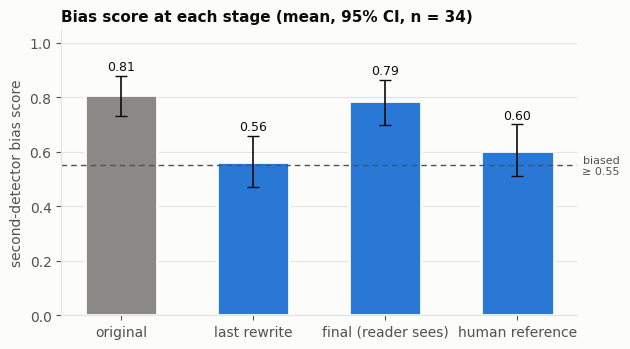

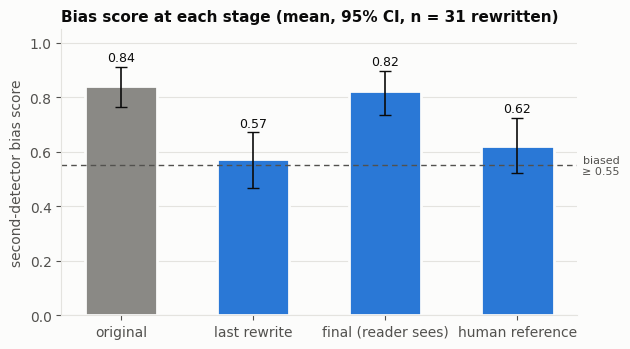

In [3]:
plots.save(plots.score_ladder(runs, plots.F_STAGES, BIASED), FIG / f"f_stages_{RULE}.png")
plots.save(plots.score_ladder(runs, plots.F_STAGES, BIASED, only_rewritten=True), FIG / f"f_stages_rewritten_{RULE}.png")

**Decisions.** What oversight did with each sentence. If both rules have been run, both rows are shown.

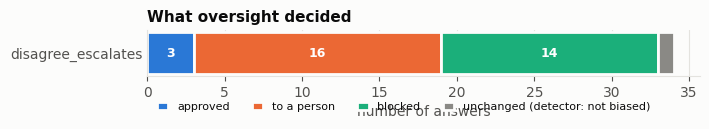

In [4]:
files = {r: ARTIFACTS / f"full_pipeline_rows_{r}.csv" for r in config.EVALUATOR_RULES}
by_rule = {r: pd.read_csv(f, keep_default_na=False) for r, f in files.items() if f.exists()}
plots.save(plots.decisions(by_rule), FIG / "f_decisions.png")
if len(by_rule) > 1:
    plots.save(plots.cost(by_rule), FIG / "f_cost.png")

**Each sentence, before vs after.** One dot per sentence that reached the rewriter. Dots below the diagonal got less
biased; the colour is the oversight decision. The bar chart shows the same change per sentence id, sorted.

PosixPath('/content/drive/MyDrive/debias/figures/f_change_disagree_escalates.png')

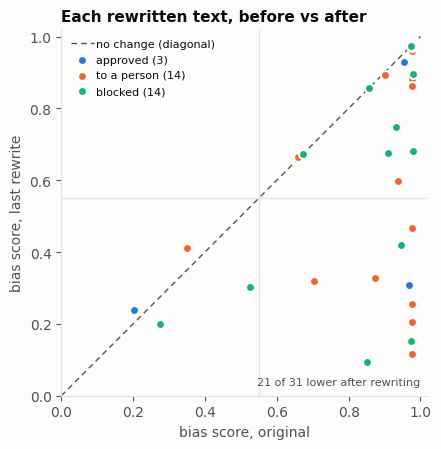

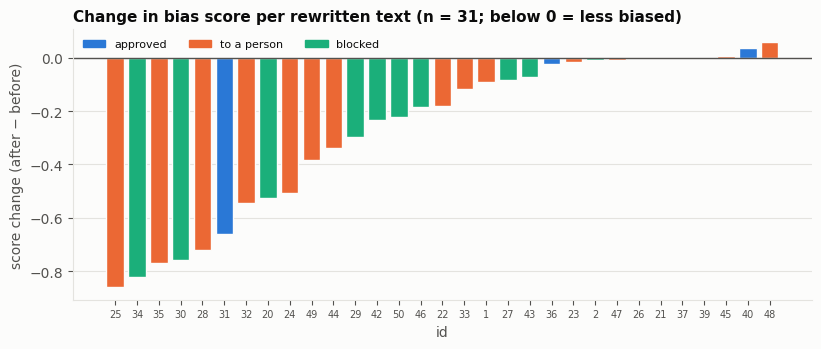

In [5]:
plots.save(plots.before_after(runs, "second_before", "second_last_rewrite", BIASED, ("original", "last rewrite")),
           FIG / f"f_before_after_{RULE}.png")
plots.save(plots.change_per_text(runs, "second_before", "second_last_rewrite"), FIG / f"f_change_{RULE}.png")

**Rewrite vs the human reference.** Below the diagonal: the rewrite scored lower than Amen's hand-written neutral
version. A rewrite far below the reference may have deleted content, not only bias: read it in section 6.

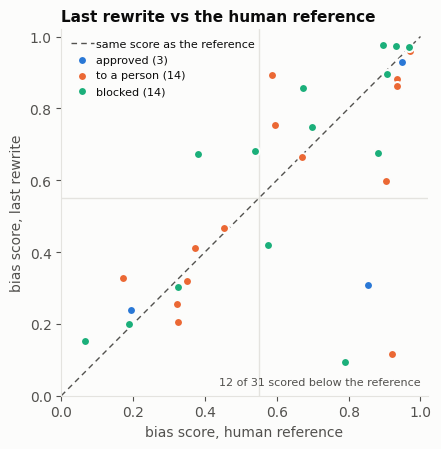

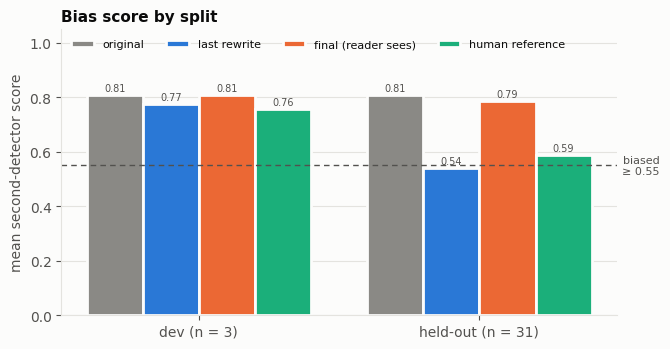

In [7]:
plots.save(plots.before_after(runs, "second_reference", "second_last_rewrite", BIASED,
                              ("human reference", "last rewrite"), title="Last rewrite vs the human reference",
                              diagonal="same score as the reference", note="{k} of {n} scored below the reference"),
           FIG / f"f_vs_reference_{RULE}.png")
if runs["split"].nunique() > 1:
    plots.save(plots.by_group(runs, "split", plots.F_STAGES, BIASED), FIG / f"f_by_split_{RULE}.png")

## How to read the results

- **Second detector drop** is the main number for the report: a clear drop on the **held-out** sentences, close to
  the reference score, means the rewrite removes bias that a separate model can see. Read it twice: the drop to
  the **last rewrite** says how good the rewriting is; the drop to the **final** answer says how much of that
  reaches users after oversight.
- **The two rules.** With `disagree_escalates`, an unfair rewrite is usually flagged only by the harmed side's
  reviewer, so it goes to a human after round 1. With `retry_first`, the same rewrite gets up to 3 rounds with
  feedback first. Compare: how many more are approved, how many fewer escalate, how much longer it takes, and
  whether the approved rewrites are still less biased. That is the evidence for the team decision.
- **Unbiased / uncertain from the main detector** on sentences that are biased by design shows what the detector
  misses: those never reach the rewriter.
- **Block** means 3 rounds were not enough: read the reviewer problems in the trace; they show which guidebook rule
  the rewriter keeps breaking.
- **Caveat.** Some test sentences come from FigNews posts, which both detectors may have seen during training.
  Their scores before the rewrite can therefore be higher than for new text; the before/after *change* is still
  fair because both scores come from the same model.
- Every run is saved with the prompt versions, the model id and the commit, so numbers from different runs can be
  compared or traced back.